# 09 · An unseen theft method, and closing the age gap (policy v1.1)

Two questions a reviewer would ask after week 10:

1. **"Your model only finds the signals you put in the simulator."** Test it on a theft method
   the model was never designed around: **barcode switching**, where a shopper scans a cheap
   item's barcode for an expensive one. The scan count matches the basket, the pace is normal and
   nothing is deleted, so the strongest signals disappear.
2. **The age gap** (week 10): younger family households were stopped about 1.6x as often as the
   oldest when honest, because their baskets are bigger. Can it be fixed, and at what cost?

Produced by `python -m smartshop.experiments.sensitivity` and
`python -m smartshop.reporting.mitigation`; this notebook reads their outputs.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from smartshop.viz import BLUE, GREY, ORANGE, TEXT_2, pct, save, set_style, subtitle

set_style()
sens = pd.read_csv('../models/sensitivity.csv').set_index('scenario')
mit = pd.read_csv('../models/fairness_mitigation.csv')

## 1. Barcode switching

Each switching world reruns the whole chain twice:

- **model retrained**: the store keeps learning from its random full rescans, as the weekly job
  does;
- **model not retrained**: the model and policy shape built for the world without switching,
  with only rescan volume reset to colleague time (a new method appears after deployment).

"Deliberate loss in the top 12% of scores" asks whether the risk ranking still points at theft
(random would be 12%).

In [2]:
rows = ['Base assumptions',
        'Barcode switching: half of theft (model retrained)',
        'Barcode switching: half of theft (model not retrained)',
        'Barcode switching: all theft (model retrained)',
        'Barcode switching: all theft (model not retrained)']
cols = ['loss reduction', 'v1.1: loss reduction', 'recovery multiple', 'v1.1: recovery multiple',
        'honest stops reduction', 'v1.1: honest stops reduction',
        'deliberate value in top 12% of scores']
sens.loc[rows, cols].round(3)

,loss reduction,v1.1: loss reduction,recovery multiple,v1.1: recovery multiple,honest stops reduction,v1.1: honest stops reduction,deliberate value in top 12% of scores
scenario,,,,,,,
Base assumptions,0.114,0.196,5.424,6.882,0.694,0.648,0.478
Barcode switching: half of theft (model retrained),0.090,0.155,4.271,5.233,0.693,0.646,0.456
Barcode switching: half of theft (model not retrained),0.088,0.141,4.167,4.973,0.691,0.641,0.448
Barcode switching: all theft (model retrained),0.053,0.085,3.215,3.690,0.684,0.629,0.389
Barcode switching: all theft (model not retrained),0.043,0.057,2.965,3.176,0.687,0.631,0.357


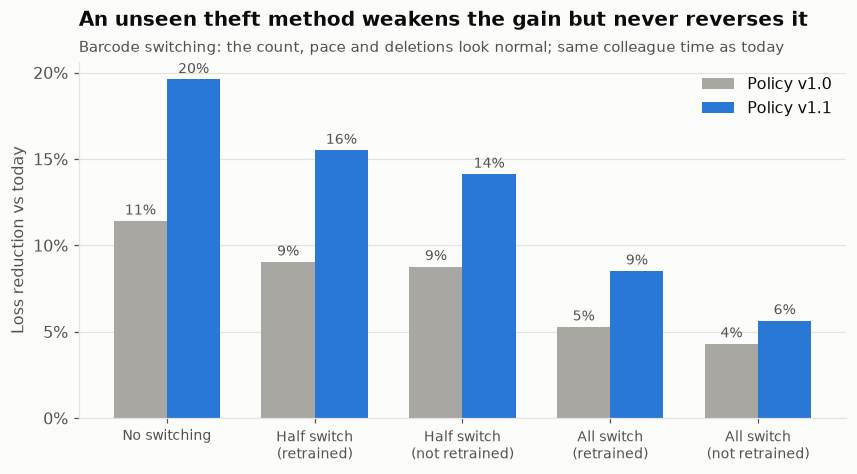

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.2))
labels = ['No switching', 'Half switch\n(retrained)', 'Half switch\n(not retrained)',
          'All switch\n(retrained)', 'All switch\n(not retrained)']
x = np.arange(len(rows))
v10 = sens.loc[rows, 'loss reduction']
v11 = sens.loc[rows, 'v1.1: loss reduction']
b1 = ax.bar(x - 0.18, v10, 0.36, color=GREY, label='Policy v1.0')
b2 = ax.bar(x + 0.18, v11, 0.36, color=BLUE, label='Policy v1.1')
for b in (b1, b2):
    ax.bar_label(b, labels=[f'{v:.0%}' for v in b.datavalues], padding=2, color=TEXT_2, fontsize=9)
ax.set_xticks(x, labels, fontsize=9)
from matplotlib.ticker import MultipleLocator

ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.yaxis.set_major_formatter(pct())
ax.set_ylabel('Loss reduction vs today')
ax.legend(frameon=False)
ax.grid(axis='x', visible=False)
ax.set_title('An unseen theft method weakens the gain but never reverses it')
subtitle(ax, 'Barcode switching: the count, pace and deletions look normal; same colleague time as today')
save(fig, '22_barcode_switching')
fig

**Reading it.**

- **The policy still beats today in every case.** Even when every thief switches barcodes and the
  model is never retrained, loss is lower, recovery is higher and honest stops fall by the same
  ~69%.
- **The gain shrinks**, as it should: the scan-log signals the model relied on are gone for
  switchers. What is left is member history: switchers' baskets hold fewer high-risk items than
  their usual Nectar baskets, so the ranking still points at theft well above chance.
- **Retraining helps a little.** Random full rescans keep finding switched items, so the weekly
  retrain learns from them.
- **The random floor is the safety net.** It catches switched items at the same rate as anything
  else, so total loss stays measurable without bias, and a rise in losses found on low-score
  sessions is the early warning that a new method has appeared.

## 2. Closing the age gap: compare like with like

The risk model learns "will a rescan find *anything*". Big baskets nearly always hold an honest
slip, so raw scores favour them, and they are also the slowest to rescan. Younger family
households buy the biggest baskets, hence the gap.

The fix: compare each session only with sessions of a similar size (its rank within a band of
units scanned, mapped back onto the overall score distribution), blended with the raw score at a
chosen **strength**. It uses only units scanned, which the store sees; no demographics. The
strength was **chosen on the tuning period** (days 331–500); the table is the test period, run as
the policy would operate (shoppers respond, trust over four cycles, 10 runs).

In [4]:
show = mit[['strength', 'tuning: loss reduction vs today', 'loss reduction vs today',
            'recovery multiple', 'honest stops', 'age group: four-fifths ratio', 'age group: verdict',
            'household size: four-fifths ratio', 'new SmartShop user (<5 sessions): four-fifths ratio']]
show.round(3)

,strength,tuning: loss reduction vs today,loss reduction vs today,recovery multiple,honest stops,age group: four-fifths ratio,age group: verdict,household size: four-fifths ratio,new SmartShop user (<5 sessions): four-fifths ratio
0,0.00,0.124,0.117,5.553,1682.614,0.611,review,0.636,0.979
1,0.25,0.159,0.162,6.439,1752.644,0.634,review,0.678,0.916
2,0.50,0.195,0.197,7.119,1918.179,0.689,gap within chance for groups this small,0.720,0.883
3,0.75,0.214,0.218,7.441,2192.741,0.837,pass,0.806,0.849
4,1.00,0.207,0.228,7.366,2597.569,0.897,pass,0.844,0.800


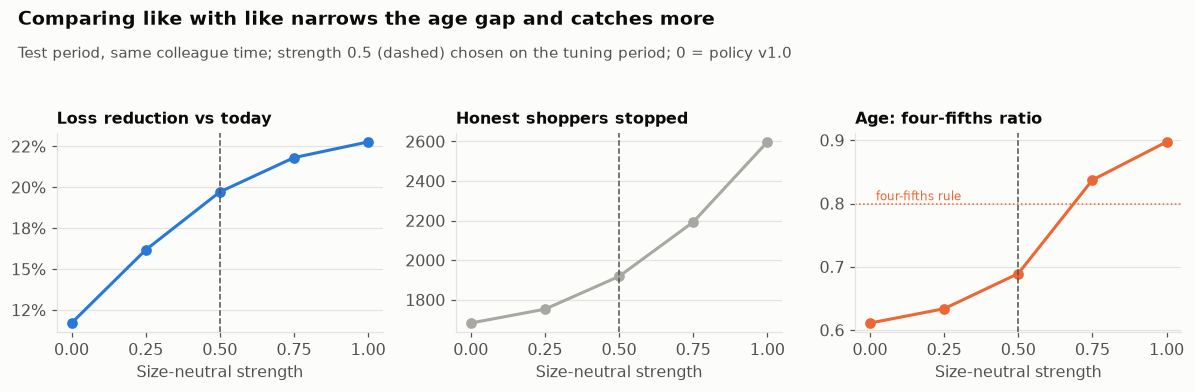

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
x = mit.strength
panels = [
    ('Loss reduction vs today', mit['loss reduction vs today'], BLUE, pct(), None),
    ('Honest shoppers stopped', mit['honest stops'], GREY, None, None),
    ('Age: four-fifths ratio', mit['age group: four-fifths ratio'], ORANGE, None, 0.8),
]
for ax, (title, y, color, fmt, line) in zip(axes, panels):
    ax.plot(x, y, marker='o', color=color)
    ax.axvline(0.5, color=TEXT_2, lw=1, ls='--')
    if line:
        ax.axhline(line, color=ORANGE, lw=1, ls=':')
        ax.text(0.02, line + 0.005, 'four-fifths rule', color=ORANGE, fontsize=8)
    if fmt:
        ax.yaxis.set_major_formatter(fmt)
    ax.set_title(title, fontsize=10.5, pad=6)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
    ax.set_xlabel('Size-neutral strength')
fig.suptitle('Comparing like with like narrows the age gap and catches more', x=0.02, ha='left',
             fontweight='bold', fontsize=12.5)
fig.text(0.02, 0.86, 'Test period, same colleague time; strength 0.5 (dashed) chosen on the tuning period; '
         '0 = policy v1.0', color=TEXT_2, fontsize=9.5)
fig.tight_layout(rect=(0, 0, 1, 0.86))
save(fig, '23_size_neutral')
fig

**Why it catches more, not less.** Rescans move away from slow 40+ item baskets full of honest
slips towards sessions that look unusual *for their size*. Each rescan is quicker, so more fit in
the same colleague time, and a larger share land on deliberate non-scanning. The cost is more
honest shoppers stopped than v1.0 (though still far fewer than today), and at full strength new
SmartShop users reach the edge of the four-fifths rule. At 0.5 the age ratio rises from 0.61 to
0.69, which the permutation test can no longer tell apart from chance for groups this small.
Strength 0.5 balances the three and becomes **policy v1.1**: served by the API, recalibrated weekly, and shown on the dashboard.

## Findings

| # | Finding | Implication |
|---|---|---|
| 1 | Barcode switching, a method the model was not built for, weakens the gain but never reverses it: even with every thief switching and no retraining, the policy beats today on loss, recovery and honest stops | The result does not rest only on the signals the simulator planted |
| 2 | Member history keeps the ranking pointing at theft when scan-log signals vanish; retraining on random full rescans recovers part of the gap | Keep the floor and the weekly retrain; watch finds on low-score sessions as an early warning |
| 3 | Scoring each session against others of a similar size narrows the age gap (0.61 to 0.69 at strength 0.5, no longer distinguishable from chance; 0.90 at full strength) and cuts loss further at the same colleague time, for more honest stops than v1.0 | **Policy v1.1** (strength 0.5) |
| 4 | The gain comes from cost: big baskets are slow to rescan and mostly hold honest slips | The v1.0 score answered "will a rescan find anything", not "is this rescan worth a colleague's time" |